# Python calling C

Notebook 03 left a puzzle: C multiplies matrices hundreds of times faster than Python, yet Python is the main language of AI. This notebook solves it, starting with a surprising measurement.

## NumPy against our C code

The same multiplication of two 1024 × 1024 matrices, with our best C version from notebook 03 and with NumPy's `@` operator, one line of Python:

In [ ]:
import numpy as np

from compare_efficiency.benchmark import gflops, random_matrices, time_function
from compare_efficiency.c_library import call_c_matmul, compile_c_library, load_c_library

c_library_path = compile_c_library(["-O3", "-march=native"], "O3")
c_library = load_c_library(c_library_path)
matrix_a, matrix_b = random_matrices(1024)

np.allclose(call_c_matmul(c_library.matmul_ikj, matrix_a, matrix_b), matrix_a @ matrix_b)

True

In [ ]:
c_seconds = time_function(lambda: call_c_matmul(c_library.matmul_ikj, matrix_a, matrix_b), repeats=3)
numpy_seconds = time_function(lambda: matrix_a @ matrix_b, warmup=3)
{"our C code": f"{c_seconds * 1000:.1f} ms", "NumPy": f"{numpy_seconds * 1000:.1f} ms"}

{'our C code': '58.4 ms', 'NumPy': '2.1 ms'}

In GFLOPS, which can be compared across sizes, together with the pure Python result from notebook 03 (measured here again at $n = 256$):

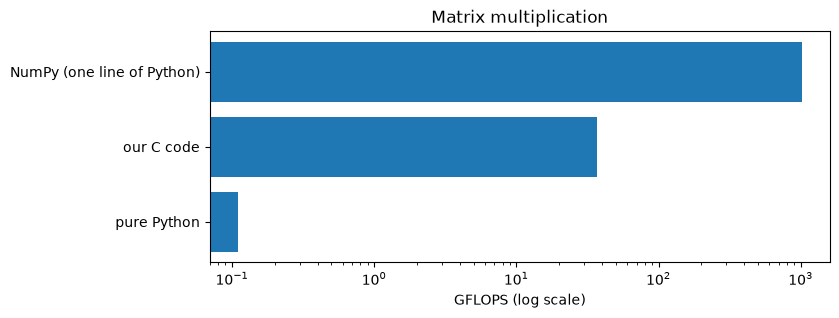

In [ ]:
import matplotlib.pyplot as plt

from compare_efficiency.matmul_pure_python import matmul_pure_python

list_a, list_b = (matrix.tolist() for matrix in random_matrices(256))
python_seconds = time_function(lambda: matmul_pure_python(list_a, list_b), repeats=1)

speed_in_gflops = {
    "pure Python": gflops(256, python_seconds),
    "our C code": gflops(1024, c_seconds),
    "NumPy (one line of Python)": gflops(1024, numpy_seconds),
}

figure, axis = plt.subplots(figsize=(8, 3))
axis.barh(list(speed_in_gflops), list(speed_in_gflops.values()))
axis.set_xscale("log")
axis.set_xlabel("GFLOPS (log scale)")
axis.set_title("Matrix multiplication")
plt.show()

A single line of Python is not only thousands of times faster than the Python loops: it is also many times faster than our hand-written C. How is that possible, if Python is so slow?

## NumPy is compiled C code

The answer is that NumPy's heavy work is not written in Python at all. NumPy is a Python package whose core is written in C and compiled in advance. Its most important piece is a compiled **shared library** file (`.so` on Linux and macOS, `.pyd` on Windows), exactly the same kind of file that notebook 03 built from our C code:

In [ ]:
from pathlib import Path

numpy_folder = Path(np.__file__).parent
[path.name for path in numpy_folder.rglob("_multiarray_umath*") if path.suffix in {".so", ".pyd"}]

['_multiarray_umath.cpython-314-x86_64-linux-gnu.so']

In [ ]:
c_library_path.name

'libmatmul_O3.so'

NumPy also installs other compiled libraries next to it. One of them has `blas` in its name; the next sections explain what it is (the files are in `numpy.libs` on Linux and Windows, and in `numpy/.dylibs` on macOS):

In [ ]:
bundled_library_folders = [numpy_folder.parent / "numpy.libs", numpy_folder / ".dylibs"]
[path.name for folder in bundled_library_folders if folder.exists() for path in folder.iterdir()]

['libgfortran-83c28eba-468e71e5.so.5.0.0',
 'libscipy_openblas64_-f48b354e.so',
 'libquadmath-2284e583-a9307bba.so.0.0.0']

So when you write `matrix_a @ matrix_b`, Python does very little: it finds the right compiled function inside one of NumPy's library files and hands it the memory addresses of the two arrays. The multiplications themselves run in compiled code, with no interpreter involved. It is the same thing we did by hand with `ctypes` in notebook 03, just packaged so neatly that it looks like ordinary Python.

## Moving the loop into C

This works for simple operations too. Adding up 10 million numbers with a Python loop, and with NumPy's `sum()`:

In [ ]:
numbers = np.random.default_rng(0).random(10_000_000)
numbers_as_list = numbers.tolist()

def sum_with_python_loop(values: list[float]) -> float:
    total = 0.0
    for value in values:
        total += value
    return total

python_loop_seconds = time_function(lambda: sum_with_python_loop(numbers_as_list), repeats=3)
numpy_sum_seconds = time_function(lambda: numbers.sum(), repeats=3)
f"Python loop: {python_loop_seconds * 1000:.0f} ms, NumPy: {numpy_sum_seconds * 1000:.1f} ms"

'Python loop: 66 ms, NumPy: 1.9 ms'

Both versions are started from Python. The difference is **where the loop runs**: in the interpreter, one step at a time, or inside NumPy's compiled C code, over bare numbers stored side by side. Replacing Python loops with whole-array operations like this is called **vectorisation** (notebook 02 called `a + b` on arrays a *vectorised* operation). It is the most important habit for writing fast numerical Python.

## BLAS: a library specialised in matrices

For matrix multiplication, NumPy goes one step further: it does not even use its own C code. It calls **BLAS** (*Basic Linear Algebra Subprograms*), a library dedicated to vector and matrix operations. BLAS is compiled code as well (written in C, Fortran and, for the most critical parts, directly in machine instructions), and experts optimise it separately for each family of processors. NumPy is installed together with one of these libraries.

That is why it beats our C code, even though both are compiled:

- It organises the work in **small blocks** that stay close to the processor while they are reused, instead of fetching the same numbers from memory again and again (the effect we saw with loop order in notebook 03, taken much further).
- It uses the processor's special instructions that operate on **several numbers at once**.
- It uses **all the cores**. A modern CPU contains several **cores**: independent processing units, each able to run its own work, like several cooks in one kitchen. Our C code used one; BLAS splits the matrix between all of them.

In [ ]:
import os

from threadpoolctl import threadpool_info

{"logical processors": os.cpu_count(),
 "BLAS library used by NumPy": [library["internal_api"] for library in threadpool_info()]}

{'logical processors': 24, 'BLAS library used by NumPy': ['openblas']}

→ Deep dive: [Inside BLAS](deep-dives/inside_blas.ipynb) measures the effect of threads, and explains how a BLAS routine organises its work.

## The same pattern everywhere

NumPy is not an exception. The whole AI ecosystem is built the same way: a comfortable Python interface on top of a compiled core.

| Library | What it is used for | Where the heavy work runs |
|---|---|---|
| NumPy | Arrays and linear algebra | C, plus BLAS |
| pandas | Data tables | C and Cython (a compiled variant of Python), plus NumPy |
| scikit-learn | Classic machine learning | Cython, C and C++, plus NumPy and SciPy |
| PyTorch | Deep learning | C++, and CUDA on graphics cards |
| TensorFlow | Deep learning | C++, and CUDA on graphics cards |
| Hugging Face tokenizers | Splitting text into tokens | Rust |

This is why Python is called a **glue language**: it is used to describe *what* to compute and to connect fast components written in other languages, which do the actual computing. The interpreter's slowness only costs a little on each *call*, not on each of the billions of operations inside it. So the rule for fast Python in AI is: **few calls, each doing a lot of work**, which is also why models process examples in batches.

When no library does what you need, there are also tools that compile your own Python functions to machine code.

→ Deep dive: [Compiling Python](deep-dives/compiling_python.ipynb) compares Numba, Cython and PyPy.

## Key ideas

- NumPy's operations run in **compiled C code**, stored in shared library files just like the one we built in notebook 03. Python only makes the call.
- **Vectorisation** moves loops out of the interpreter and into compiled code.
- For matrix multiplication NumPy calls **BLAS**, an expert-tuned library that uses memory well, processes several numbers per instruction and uses all the cores. It beats simple hand-written C.
- Python is the **glue language** of AI: pandas, scikit-learn, PyTorch and TensorFlow all follow the same pattern of a Python interface over a compiled core.